# Attention-based Neurosymbolic Differentiable Rule Extractor (ANDRE)

**Creator**: Iman Sharifi

### Learning the rules for Even/Odd numbers from a generic dataset

In [1]:
import numpy as np
import torch
import torch.nn.functional as F

def interpret_neuron_weights_entropy_(body_preds, pred_values, Weights, data_type='boolean', entropy_threshold=1.5):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        body_preds (list): A list of predicate strings for each neuron, like ['b1', 'b2', ...] or ['b1(X1, X2)', 'b2(X3)', ...]
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    
    interpretations = []
    if data_type == 'fuzzy':
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            # Find predicate value of a given neuron
            pred_value = pred_values[i]
            body_pred = body_preds[i]

            # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
            new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

            max_index = np.argmax(new_weights)
            if max_index == 0:
                interpretations.append(f'{body_pred}')
                continue
            elif max_index == 1:
                interpretations.append(f'not({body_pred})')
                continue
            else:
                interpretations.append('1')
    else:
        # For boolean data type, we assume pred_values are binary (0 or 1)
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            max_index = np.argmax(weights)

            if max_index == 0:
                interpretations.append(f'{body_preds[i]}')
            elif max_index == 1:
                interpretations.append(f'not({body_preds[i]})')
            else:
                interpretations.append('1')

    return interpretations

def interpret_neuron_weights_entropy(pred_values, Weights, data_type='boolean', entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1',
    only if entropy is below a threshold to ensure confidence in prediction.

    Args:
        pred_values (numpy.ndarray): A 1D array with predicate values (between 0 and 1).
        Weights (list of list): A 2D list where each row is the softmaxed weights of a neuron.
        data_type (str): The type of data, either 'boolean' or 'fuzzy'.
        entropy_threshold (float): The threshold of entropy above which output is considered uncertain.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron, or '?' for uncertain.
    """
    interpretations = []
    if data_type == 'fuzzy':
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            pred_value = pred_values[i]
            new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
            max_index = np.argmax(new_weights)

            if max_index == 0:
                interpretations.append(f'b{i+1}')
            elif max_index == 1:
                interpretations.append(f'not(b{i+1})')
            else:
                interpretations.append('1')
    else:
        # For boolean data type, we assume pred_values are binary (0 or 1)
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            max_index = np.argmax(weights)

            if max_index == 0:
                interpretations.append(f'b{i+1}')
            elif max_index == 1:
                interpretations.append(f'not(b{i+1})')
            else:
                interpretations.append('1')

    return interpretations

# Network

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input
    
# class CustomNeuron(nn.Module):
#     def __init__(self):
#         super(CustomNeuron, self).__init__()
#         self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

#     def forward(self, x):
#         # weights = torch.sigmoid(self.raw_weights)
#         weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1

#         x1 = x
#         x2 = 1 - x
#         x3 = torch.ones_like(x)
#         X1 = weights[0] * x1
#         X2 = weights[1] * x2
#         X3 = weights[2] * x3
#         attention_weights = torch.softmax(20 * torch.stack([X1, X2, X3]), dim=0)
#         X1 = attention_weights[0] * X1
#         X2 = attention_weights[1] * X2
#         X3 = attention_weights[2] * X3
#         activated_input = X1 + X2 + X3
#         return activated_input

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(10*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(10*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        # self.weights = torch.sigmoid(self.raw_weights)
        # # Normalize weights to sum to 1
        # self.weights = self.weights / self.weights.sum()
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3

        # Fuzzy OR operation using the weights
        fuzzy_or = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3)

        return torch.log(fuzzy_or)

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])
        # self.raw_rule_weights = nn.Parameter(torch.randn(num_rules))  # Initialize rule weights
        self.raw_sigmoid_center_weight = nn.Parameter(torch.randn(num_rules) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []
        self.adjust_sigmoid_center = 0.5 * torch.sigmoid(self.raw_sigmoid_center_weight)  # Ensure sigmoid center is between 0 and 0.5

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            rule_output = torch.exp(sum(conjunctions))
            activated_rule_output = torch.sigmoid(5 * (rule_output - self.adjust_sigmoid_center[i]))
            rule_outputs.append(activated_rule_output)

        # Multiply the rule outputs with the rule weights
        # print("Rule Weights:", self.rule_weights)
        # rule_outputs = [output * weight for output, weight in zip(rule_outputs, self.rule_weights)]
        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r

        return fuzzy_or

In [16]:
def compute_acc_ratio(model, x, y, rule_idx):
    with torch.no_grad():
        rule = model.rules[rule_idx]
        body_conj = sum(rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule))
        rule_weights = []
        for neuron in rule:
            weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
            rule_weights.append(weights)

        num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.round(w[2]) == 1.0])
        threshold = 0.5**(num_body_preds)
        body = (torch.exp(body_conj) >= threshold).float()

        # Match the shape of body with y
        if body.shape != y.shape:
            body = body.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(body, y)

        return cos_sim.item()

def compute_acc_ratio_all_rules(model, x, y):
    with torch.no_grad():
        for rule_idx, rule in enumerate(model.rules):
            pred_values = [rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule)]
            rule_weights = []
            for neuron in rule:
                weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
                rule_weights.append(weights)

            # This should be double checked because it may not be accurate
            num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.argmax(w) == 2 and np.round(w[2]) == 1.0]) # x.shape[1] is the number of potential body predicates
            threshold = 0.5**(num_body_preds)
            body = (torch.exp(body_conj) >= threshold).float()

            if rule_idx == 0:
                fuzzy_or = body
            else:
                fuzzy_or = fuzzy_or + body - fuzzy_or * body

        # Match the shape of body with y
        if fuzzy_or.shape != y.shape:
            fuzzy_or = fuzzy_or.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(fuzzy_or, y)

        return cos_sim.item()

# Fix mismatched    
# def compute_acc_ratio_all_rules_(model, x, y):
#     with torch.no_grad():
#         rule_outputs = []
#         for rule in model.rules:
#             conjunctions = []
#             for i, neuron in enumerate(rule):
#                 xi = x[:, [i % model.input_dim]]
#                 conjunctions.append(neuron(xi))
#             # Soft min of neuron outputs using attention mechanism
#             # find -beta * outputs for all neurons, where beta is a hyperparameter
#             attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
#             outputs = [attention_weights[i] * conjunctions[i] for i in range(model.num_neurons)]
#             activated_outputs = torch.sigmoid(5*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
#             rule_outputs.append(activated_outputs)

#         # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
#         # find BETA * rule_outputs for all rules, where beta is a hyperparameter
#         attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
#         rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(model.num_rules)]
#         activated_output = torch.sigmoid(5*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

#         # find cosine similarity between body and y
#         cos_sim = nn.CosineSimilarity(dim=0)(activated_output, y)

#         return cos_sim.item()

def compute_acc_ratio_all_rules_attention(model, x, y, beta=10.0):
    with torch.no_grad():
        rule_outputs = []
        for rule in model.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % model.input_dim]]
                conjunctions.append(neuron(xi).squeeze())
            # Softmin attention over neurons (optional, or just use sum)
            conjunctions = torch.stack(conjunctions, dim=1)  # (batch, num_neurons)
            attention_weights = torch.softmax(-beta * conjunctions, dim=1)
            outputs = (attention_weights * conjunctions).sum(dim=1)  # (batch,)
            activated_outputs = torch.sigmoid(5 * (outputs - 0.5))
            rule_outputs.append(activated_outputs)

        # Stack rule outputs: shape (num_rules, batch)
        rule_outputs_tensor = torch.stack(rule_outputs, dim=0)  # (num_rules, batch)
        # Softmax attention over rules for each sample (dim=0)
        attention_weights = torch.softmax(beta * rule_outputs_tensor, dim=0)
        # Weighted sum over rules for each sample
        final_output = (attention_weights * rule_outputs_tensor).sum(dim=0)  # (batch,)
        # Compute accuracy
        preds = (final_output > 0.5).float()
        acc = (preds == (y > 0.5)).float().mean().item()
        return acc

# compute_acc_ratio(best_model, X_train, y_train, 0)

## The most stable version of the code:

1 - Added Multiple Initial values

2 - Added entropy for weight exploration 

## Learning More than one rule using NSDRE

## Example rule: 

### $h \leftarrow h_1 \vee h_2$

- $h_1 \leftarrow b_1 \wedge \neg b_2$

- $h_2 \leftarrow b_3 \wedge b_4$

Num Rules: 1, Restart 1/3, Final Loss: 0.4164.
Overall accuracy ratio: 0.6850
Num Rules: 1, Restart 2/3, Final Loss: 0.4061.
Overall accuracy ratio: 0.7850
Num Rules: 1, Restart 3/3, Final Loss: 0.4171.
Overall accuracy ratio: 0.6850
Num Rules: 2, Restart 1/3, Final Loss: 0.0111.
Overall accuracy ratio: 1.0000
Num Rules: 2, Restart 2/3, Final Loss: 0.0112.
Overall accuracy ratio: 1.0000
Num Rules: 2, Restart 3/3, Final Loss: 0.1532.
Overall accuracy ratio: 0.9400


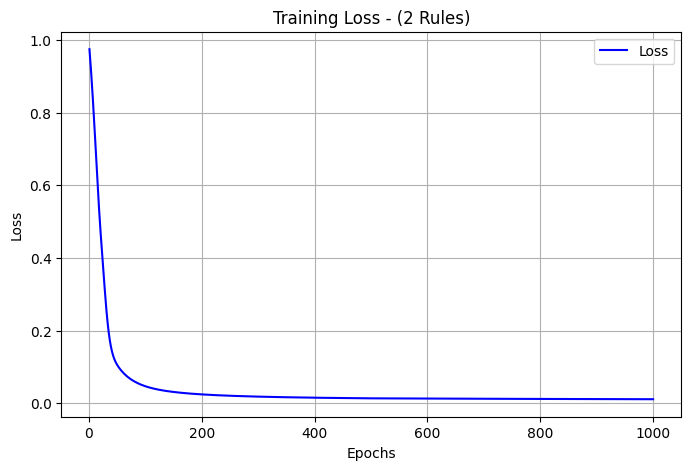


Final Weights of the Network:
Rule 1: [[0.770422637462616, 0.12261264771223068, 0.10696471482515335], [0.11207003891468048, 0.1437547206878662, 0.7441751956939697], [0.11930876970291138, 0.7813704609870911, 0.09932076185941696], [0.12509293854236603, 0.07447183132171631, 0.8004352450370789]]
Rule 2: [[0.13655681908130646, 0.11584065854549408, 0.7476024627685547], [0.11141563206911087, 0.775489866733551, 0.1130945235490799], [0.12066245079040527, 0.08840005844831467, 0.7909374237060547], [0.7892783880233765, 0.09783884882926941, 0.11288268864154816]]

Final SubRules:
Rule 1: h :- b1 and not(b3). -> Accuracy: 1.0 

Rule 2: h :- not(b2) and b4. -> Accuracy: 1.0 


Final Rule:
h :- b1 and not(b3) OR not(b2) and b4.


In [22]:
from collections import Counter
# Parameters
Num_rules = 2
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 200
num_epochs = 1000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = (torch.rand(num_samples, input_dim) > 0.5).float()  # Random binary features
y_train = ((((1 - X_train[:, 1]) > 0.5) & (X_train[:, 3] > 0.5))|((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5))).float()
# y_train = ((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5)).float()
# y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float()

# define y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float() using &
# y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5))).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_acc_ratio = 0
best_losses = []

for num_rules in range(Num_rules):

    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules + 1, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            # total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            total_loss = bce_loss #- entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            # best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

        # Compute acc_ratio on training data
        # for r in range(len(model_nsre.rules)):
        #     acc_ratio = compute_acc_ratio(model_nsre, X_train, y_train, r)
        #     print(f"Rule {r + 1} accuracy ratio: {acc_ratio:.4f}")
        acc_ratio_all = compute_acc_ratio_all_rules_attention(model_nsre, X_train, y_train)
        if acc_ratio_all > best_acc_ratio:
            best_acc_ratio = acc_ratio_all
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_num_rules = num_rules + 1

        print(f"Overall accuracy ratio: {acc_ratio_all:.4f}")
# Load the best model
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)
print("\nFinal Weights of the Network:")
for i, weights in enumerate(Weights_nsre):
    print(f"Rule {i+1}: {weights}")

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_entropy(pred_values, weights, data_type='boolean', entropy_threshold=1.5)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    rule_accuracy = float(count/len(Extracted_rules))
    # print(f"The most repeated rule is: '{most_common_rule}'")
    # print(f"Accuracy over training data: {rule_accuracy}.")
    # Save the most common rule with its accuracy
    Final_rules.append((most_common_rule, rule_accuracy))

# Sort rules by accuracy
Final_rules.sort(key=lambda x: x[1], reverse=True)
# Extract the rules from the sorted list
Final_rules_ = [rule[0] for rule in Final_rules]
# Print the final rules with their accuracies
print("\n======================================")
print("Final SubRules:")
for i, rule in enumerate(Final_rules):
    print(f"Rule {i+1}: {rule[0]} -> Accuracy: {rule[1]} \n")

# remove the "h :- " part from each rule
Final_rules = [rule.replace(f"h :- ", "") for rule_num, rule in enumerate(Final_rules_)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


In [24]:
import torch
import re

def create_V_matrix(predicates):
    # Extract all variable names
    variable_set = set()
    predicate_vars = []
    for pred in predicates:
        # Extract variables inside parentheses
        vars_in_pred = re.findall(r'\((.*?)\)', pred)
        if vars_in_pred:
            vars_list = [v.strip() for v in vars_in_pred[0].split(',')]
        else:
            vars_list = []
        predicate_vars.append(vars_list)
        variable_set.update(vars_list)
    # Sort variables for consistent column order
    variables = sorted(variable_set, key=lambda x: (int(x[1:]) if x[1:].isdigit() else x))
    var_idx = {v: i for i, v in enumerate(variables)}
    # Build the matrix
    V = torch.zeros((len(predicates), len(variables)), dtype=torch.float32)
    for i, vars_list in enumerate(predicate_vars):
        for v in vars_list:
            V[i, var_idx[v]] = 1.0
    return V, variables

## Network

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
LAMBDA = 10.0  # Example value for lambda

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input
    
# class CustomNeuron(nn.Module):
#     def __init__(self):
#         super(CustomNeuron, self).__init__()
#         self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

#     def forward(self, x):
#         # weights = torch.sigmoid(self.raw_weights)
#         self.weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1

#         x1 = x
#         x2 = 1 - x
#         x3 = torch.ones_like(x)
#         X1 = self.weights[0] * x1
#         X2 = self.weights[1] * x2
#         X3 = self.weights[2] * x3
#         attention_weights = torch.softmax(20 * torch.stack([X1, X2, X3]), dim=0)
#         X1 = attention_weights[0] * X1
#         X2 = attention_weights[1] * X2
#         X3 = attention_weights[2] * X3
#         activated_input = X1 + X2 + X3
#         return activated_input

# Define FuzzyDisjunctionNet
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])  # 1 - w3

            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

V_matrix:
 tensor([[1., 1., 0.],
        [1., 0., 0.],
        [0., 1., 1.],
        [1., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/5 Final Loss: 0.2008
Restart 2/5 Final Loss: 0.2008
Restart 3/5 Final Loss: 0.2006
Restart 4/5 Final Loss: 0.2007
Restart 5/5 Final Loss: 0.2011


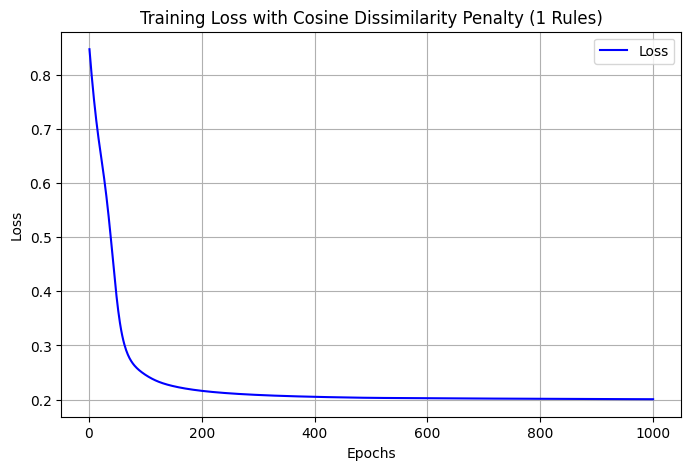

The most repeated rule is: 'h1 :- not(b1(X1, X2)) and b3(X2, X3).'
It appears 191 times out of 500.

Final Rule:
h :- not(b1(X1, X2)) and b3(X2, X3).

Final M matrices:
M1: [1.7044413089752197, 1.451138973236084, 1.2401318550109863]


In [ ]:
# Re-execution after kernel reset
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter

# Parameters
num_rules = 1
num_neurons_per_rule = 4
input_dim = 4
num_samples = 500
num_epochs = 1000
num_restarts = 5
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
y_train = ((1 - X_train[:, 0]) * X_train[:, 2] > 0.25).float()

# Body predicates and their variables
# B = {b1(X1, X2), b2(X1), b3(X2, X3), b4(X1, X3)}
predicates = ["b1(X1, X2)", "b2(X1)", "b3(X2, X3)", "b4(X1, X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

# Define head variables
head_vars = [0, 2]  # Variables X1 and X3 are the head variables
# Define auxiliary variables
connected_vars = [1]  # Variable X2 is the auxiliary variable

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)
        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        # range_restricted_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
        # range_restricted_loss is computed using this function: F(x) = sigmoid(-10 * (x - 0.5))
        range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        M_connected = [M[i][connected_vars] for i in range(num_rules)]

        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        import math
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term + 0.1 * range_restricted_loss + 0.1 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {M}")

## Even Dataset

In [23]:
import numpy as np

# Define the number range
numbers = list(range(21))  # 0 to 100
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

def encode_predicates(x1, x2, x3):
    # Each predicate returns True/False
    predicates = [
        int(x1 == 0),                 # zero(X1)
        int(x2 == 0),                 # zero(X2)
        int(x3 == 0),                 # zero(X3)
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))              # target(X2)
    ]
    # predicates = [
    #     int(x2 == x1 + 1),            # successor(X1, X2)
    #     int(x3 == x2 + 1),            # successor(X2, X3)
    #     int(x3 == x1 + 1),            # successor(X1, X3)
    #     int(is_even(x1))             # target(X1)
    # ]
    return predicates

# Construct the dataset
for x1 in numbers:
    for x2 in numbers:
        for x3 in numbers:
            x_feats = encode_predicates(x1, x2, x3)
            label = int(is_even(x3))  # target(X3) as label
            X_train.append(x_feats)
            y_train.append(label)

# Convert to numpy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)

# # Replace all 1 elements in X_train with 0.9
# X_train[X_train == 1] = 0.9
# Replace all 0 elements in X_train with 0.1
X_train[X_train == 0] = 0.01
print("X_train shape:", X_train.shape)  # Should be (101*101*101, 8)
print("y_train shape:", y_train.shape)


X_train shape: (9261, 8)
y_train shape: (9261,)


In [40]:
import numpy as np

# Limit the number range for faster experimentation
max_n = 20
numbers = list(range(max_n + 1))  # 0 to max_n
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

# def encode_predicates(x1, x2, x3):
#     predicates = [
#         int(x1 == 0),                 # zero(X1)
#         int(x2 == 0),                 # zero(X2)
#         int(x3 == 0),                 # zero(X3)
#         int(x2 == x1 + 1),            # successor(X1, X2)
#         int(x3 == x2 + 1),            # successor(X2, X3)
#         int(x3 == x1 + 1),            # successor(X1, X3)
#         int(is_even(x1)),             # target(X1)
#         int(is_even(x2))              # target(X2)
#     ]
#     return predicates
def encode_predicates(x1, x2, x3):
    predicates = [
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))             # target(X2)
    ]
    return predicates
# Focused rule chains: X1=i, X2=i+1, X3=i+2 to align with recursive rule structure
for i in range(max_n - 1):  # Ensure i+2 <= max_n
    x1 = i
    x2 = i + 1
    x3 = i + 2
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))  # target(X3) as label
    X_train.append(x_feats)
    y_train.append(label)

# Add a few noise samples with random triples
np.random.seed(42)
for _ in range(10):
    x1, x2, x3 = np.random.choice(numbers, 3, replace=True)
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))
    X_train.append(x_feats)
    y_train.append(label)

# Convert to numpy arrays
X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

# # Replace all 1 elements in X_train with 0.9
# X_train[X_train == 1] = 0.9
# Replace all 0 elements in X_train with 0.1
X_train[X_train == 0] = 0.01
print("X_train shape:", X_train.shape)  # Should be (101*101*101, 8)
print("y_train shape:", y_train.shape)

X_train shape: (29, 5)
y_train shape: (29,)


In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
LAMBDA = 10.0  # Example value for lambda

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(0.2*self.raw_weights, dim=0)
        # self.weights = torch.sigmoid(self.raw_weights)  # Use sigmoid to ensure weights are in [0, 1]
        # self.weights = self.weights / self.weights.sum()  # Normalize weights to sum to 1
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input
    
# class CustomNeuron(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

#     def forward(self, x, beta=1.0):
#         self.weights = torch.softmax(self.raw_weights, dim=0)
#         x1 = x
#         x2 = 1 - x
#         x3 = torch.ones_like(x)
#         X = torch.stack([weights[0] * x1, weights[1] * x2, weights[2] * x3], dim=0)  # (3, batch, 1)
#         attention_weights = torch.softmax(beta * X, dim=0)
#         activated_input = (attention_weights * X).sum(dim=0)  # (batch, 1)
#         return activated_input.squeeze(-1)

# Define FuzzyDisjunctionNet
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])  # 1 - w3

            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

Restart 1/1 Final Loss: 0.4874


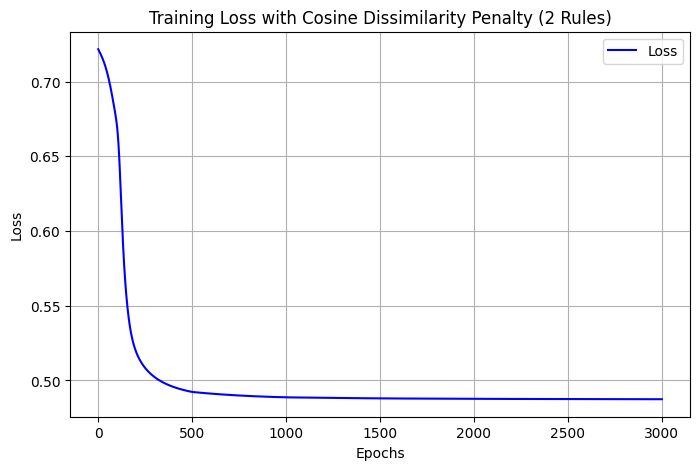


Final Weights of the Network:
Rule 1, Neuron 1: [0.002572788391262293, 0.004435698967427015, 0.99299156665802]
Rule 1, Neuron 2: [0.006335408426821232, 0.0030552647076547146, 0.9906094074249268]
Rule 1, Neuron 3: [0.04868635535240173, 0.5373669266700745, 0.4139467179775238]
Rule 1, Neuron 4: [0.999594509601593, 0.00020873827452305704, 0.00019673150382004678]
Rule 1, Neuron 5: [0.9995002746582031, 0.00023654478718526661, 0.0002631841052789241]
Rule 1, Neuron 6: [0.002757917158305645, 0.005245970096439123, 0.9919961094856262]
Rule 1, Neuron 7: [0.9995282888412476, 0.0002332203002879396, 0.00023853202583268285]
Rule 1, Neuron 8: [0.0036069874186068773, 0.006893328856676817, 0.9894996285438538]
Rule 2, Neuron 1: [0.0029477314092218876, 0.001468242728151381, 0.9955840706825256]
Rule 2, Neuron 2: [0.0035155245568603277, 0.0011878600344061852, 0.9952966570854187]
Rule 2, Neuron 3: [0.9993906021118164, 0.0003387546166777611, 0.000270706630544737]
Rule 2, Neuron 4: [0.0048964545130729675, 0.00

In [ ]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import math

# Parameters
Num_rules = 2
num_neurons_per_rule = 8  # Number of features in X_train
input_dim = num_neurons_per_rule
# num_samples = X_train.shape[0]  # Number of samples in X_train
num_samples = 1000  # For testing, we can use a smaller number of samples
num_epochs = 3000
num_restarts = 1

# Loss weights
sim_weight = 0.1
ent_weight = 0.01
rr_weight = 0.01
conn_weight = 0.01

# Random Dataset
torch.manual_seed(42)
input_dim = 8  # Number of features in X_train
num_neurons_per_rule = input_dim  # Number of neurons per rule

X_train = (torch.rand(num_samples, input_dim) > 0.5).float()  # Random binary features
# X_train = torch.rand(num_samples, input_dim)

# y_train = ((((X_train[:, 6] > 0.5) & (X_train[:, 3] > 0.5)) & (X_train[:, 4] > 0.5))).float()
# y_train = (((X_train[:, 6] * X_train[:, 3] * X_train[:, 4]) > 0.125) | (X_train[:, 2] > 0.5) | ((X_train[:, 4] * (1 - X_train[:, 7])) > 0.25)).float()
y_train = (((X_train[:, 6] * X_train[:, 3] * X_train[:, 4]) > 0.125) | (X_train[:, 2] > 0.5)).float()

# X_train = torch.tensor(X_train, dtype=torch.float32)
# y_train = torch.tensor(y_train, dtype=torch.float32)
# put the second column same as the first column

# Target body predicates and their variables
# We assume the model doesn't know the variables of the predicates beforehand, so we want to learn them
predicates = ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

# Variables
variables = ["X1", "X2", "X3"]  # Assuming we have 3 variables

# Define predicate-variable binary matrix 
# Here the variables are known for each predicate
# update variable_matrix to match the predicates ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

variable_matrix = torch.tensor([
    [1, 0, 0],  # zero(X1)
    [0, 1, 0],  # zero(X2)
    [0, 0, 1],  # zero(X3)
    [1, 1, 0],  # successor(X1, X2)
    [0, 1, 1],  # successor(X2, X3)
    [1, 0, 1],  # successor(X1, X3)
    [1, 0, 0],  # target(X1)
    [0, 1, 0],  # target(X2)
], dtype=torch.float32)

# Head variables for the rule
head_variables = ["X3"]  # Assuming the head variables are X3
# Define head variables indices
# Assuming the head variables are X1 and X3, we can define their indices
head_vars = [2]  # Assuming the head variables are X3
connected_vars = [0, 1]  # Auxiliary variables X1 and X2

# print("V_matrix:\n", V_matrix)
# print("Variable order:", variable_order)

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

# for num_rule in range(Num_rules):
num_rule = Num_rules - 1  # Set the number of rules to the desired value
num_rules = num_rule + 1  # Always set num_rules for training loop
for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, variable_matrix)
    criterion = nn.BCEWithLogitsLoss()
    # criterion = nn.BCELoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)
    
    losses_nsre = []
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)
        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        rr_loss_1 = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))

        # Find the MSE of the head variable probabilities with 1
        rr_loss_2 = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")
        range_restricted_loss = rr_loss_1 #rr_loss_1 + 0.1 * rr_loss_2
        range_restricted_loss = range_restricted_loss.sum()

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        # The only auxiliary variable is X2
        M_connected = [M[i][connected_vars] for i in range(num_rules)]

        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules
        connected_loss = connected_loss.sum()

        

        entropy_term = sum(model_nsre.entropies)

        # total_loss = bce_loss + ent_weight * entropy_term + rr_weight * range_restricted_loss + conn_weight * connected_loss
        total_loss = bce_loss + rr_weight * range_restricted_loss + conn_weight * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

        # print V matrix
        # print("V matrix:", model_nsre.V.detach().numpy())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre
        best_num_rules = num_rules  # Store the best number of rules

# Load best model and compute M
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim, variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
# filtered_state_dict = {k: v for k, v in best_state_dict.items() if k in model_keys}
# best_model.load_state_dict(filtered_state_dict, strict=False)
best_model.load_state_dict(best_state_dict)

_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        # weights = [weight / sum(weights) for weight in weights]  # Normalize weights to sum to 1
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal Weights of the Network:")
for i, weights in enumerate(Weights_nsre):
    for j, neuron_weights in enumerate(weights):
        print(f"Rule {i+1}, Neuron {j+1}: {neuron_weights}")

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")

Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


## Dataset Generation

In [18]:
import numpy as np

# Limit the number range for faster experimentation
max_n = 30
numbers = list(range(max_n + 1))  # 0 to max_n
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

# def encode_predicates(x1, x2, x3):
#     predicates = [
#         int(x1 == 0),                 # zero(X1)
#         int(x2 == 0),                 # zero(X2)
#         int(x3 == 0),                 # zero(X3)
#         int(x2 == x1 + 1),            # successor(X1, X2)
#         int(x3 == x2 + 1),            # successor(X2, X3)
#         int(x3 == x1 + 1),            # successor(X1, X3)
#         int(is_even(x1)),             # target(X1)
#         int(is_even(x2))              # target(X2)
#     ]
#     return predicates
def encode_predicates(x1, x2, x3):
    predicates = [
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))             # target(X2)
    ]
    return predicates
# Focused rule chains: X1=i, X2=i+1, X3=i+2 to align with recursive rule structure
for i in range(max_n - 1):  # Ensure i+2 <= max_n
    x1 = i
    x2 = i + 1
    x3 = i + 2
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))  # target(X3) as label
    X_train.append(x_feats)
    y_train.append(label)

# Add a few noise samples with random triples
np.random.seed(42)
for _ in range(10):
    x1, x2, x3 = np.random.choice(numbers, 3, replace=True)
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))
    X_train.append(x_feats)
    y_train.append(label)

# Convert to numpy arrays
X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

# # Replace all 1 elements in X_train with 0.9
# X_train[X_train == 1] = 0.9
# Replace all 0 elements in X_train with 0.1
X_train[X_train == 0] = 0.1 * np.random.rand(*X_train[X_train == 0].shape)  # Small random value instead of 0.1
print("X_train shape:", X_train.shape)  # Should be (101*101*101, 8)
print("y_train shape:", y_train.shape)

X_train shape: (39, 5)
y_train shape: (39,)


In [ ]:
import numpy as np

# Define the number range (adjust max_n for larger datasets)
max_n = 8
numbers = list(range(max_n + 1))
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

def encode_predicates(x1, x2, x3):
    return [
        int(x1 == 0),                 # zero(X1)
        int(x2 == 0),                 # zero(X2)
        int(x3 == 0),                 # zero(X3)
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))              # target(X2)
    ]

for x1 in numbers:
    for x2 in numbers:
        for x3 in numbers:
            feats = encode_predicates(x1, x2, x3)
            # Rule 1: target(X3) :- zero(X3)
            rule1 = feats[2] == 1
            # Rule 2: target(X3) :- target(X1), successor(X1, X2), successor(X2, X3)
            rule2 = feats[6] == 1 and feats[3] == 1 and feats[4] == 1
            label = int(rule1 or rule2)
            X_train.append(feats)
            y_train.append(label)

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

# Optionally, replace 0s with a small value for fuzzy logic
X_train[X_train == 0] = 0.001

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (4096, 8)
y_train shape: (4096,)


In [ ]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import math

# Parameters
Num_rules = 5
num_neurons_per_rule = X_train.shape[1]  # Number of features in X_train
input_dim = num_neurons_per_rule
num_samples = X_train.shape[0]  # Number of samples in X_train
num_epochs = 3000
num_restarts = 1

# Loss weights
sim_weight = 0.5
ent_weight = 0.01
rr_weight = 0.1
conn_weight = 0.1
fidelity_weight = 1.0

# Target body predicates and their variables
# We assume the model doesn't know the variables of the predicates beforehand, so we want to learn them
predicates = ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

# head of the rule is target(X3)

# Variables
variables = ["X1", "X2", "X3"]  # Assuming we have 3 variables

# Define predicate-variable binary matrix 
# Here the variables are known for each predicate
# update variable_matrix to match the predicates ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

variable_matrix = torch.tensor([
    [1, 0, 0],  # zero(X1)
    [0, 1, 0],  # zero(X2)
    [0, 0, 1],  # zero(X3)
    [1, 1, 0],  # successor(X1, X2)
    [0, 1, 1],  # successor(X2, X3)
    [1, 0, 1],  # successor(X1, X3)
    [1, 0, 0],  # target(X1)
    [0, 0, 1],  # target(X2)
], dtype=torch.float32)

# Head variables for the rule
head_variables = ["X3"]  # Assuming the head variables are X3
# Define head variables indices
# Assuming the head variables are X1 and X3, we can define their indices
head_vars = [2]  # Assuming the head variables are X3
connected_vars = [0, 1]  # Auxiliary variables X1 and X2

# print("V_matrix:\n", V_matrix)
# print("Variable order:", variable_order)

# Convert to tensors
X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)
# train_loader = DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=64, shuffle=True)

# Define cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

Num_rules = [1, 2, 3]  # List of rule counts to test

for num_rule in Num_rules:
    num_rules = num_rule
    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, variable_matrix)
        criterion = nn.BCELoss()
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []
        for epoch in range(num_epochs):
            epoch_loss = 0.0
            # for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model_nsre(X_tensor).squeeze()
            bce_loss = criterion(outputs, y_tensor)

            # Cosine similarity penalty
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    penalty += cosine(wi, wj).mean()

            # Range-restricted loss
            M = model_nsre.M_matrices
            M_head = [M[i][head_vars] for i in range(num_rules)]
            head_var_probs = torch.prod(torch.stack(M_head), dim=0)
            rr_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))

            # Connected loss
            M_connected = [M[i][connected_vars] for i in range(num_rules)]
            Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
            conn_loss = 0.5 * Sum_Fx / len(M_connected)

            # Entropy and Fidelity
            entropy_term = sum(model_nsre.entropies)
            # fidelity_loss = compute_batch_fidelity_loss(model_nsre, X_tensor, y_tensor, predicates)

            # Total loss
            total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term \
                            + rr_weight * rr_loss + conn_weight * conn_loss #+ fidelity_weight * fidelity_loss

            total_loss.sum().backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_loss += total_loss.sum().item()

            scheduler.step()
            losses_nsre.append(epoch_loss)

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            best_num_rules = num_rules

# Load best model and compute M
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim, variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
filtered_state_dict = {k: v for k, v in best_state_dict.items() if k in model_keys}
best_model.load_state_dict(best_state_dict)

_ = best_model(X_tensor)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")

Predicate_values = X_tensor

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


In [33]:
# create a dataframe for the dataset (X_train and y_train)
import pandas as pd
predicates = ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]
data = pd.DataFrame(X_train.numpy(), columns=[f"{pred}" for pred in predicates])
data['y=target(X3)'] = y_train.numpy()
data.head(20)

,zero(X1),zero(X2),zero(X3),"successor(X1, X2)","successor(X2, X3)","successor(X1, X3)",target(X1),target(X2),y=target(X3)
0,0.882269,0.915004,0.382864,0.959306,0.390448,0.600895,0.256572,0.793641,0.0
1,0.940771,0.133186,0.934598,0.593580,0.869404,0.567715,0.741094,0.429404,1.0
2,0.885443,0.573904,0.266580,0.627449,0.269632,0.441364,0.296921,0.831685,0.0
3,0.105315,0.269495,0.358813,0.199364,0.547192,0.006160,0.951555,0.075266,0.0
4,0.886014,0.583210,0.337648,0.808975,0.577925,0.903982,0.554660,0.342313,1.0
5,0.634342,0.364410,0.710429,0.946411,0.789030,0.281414,0.788632,0.589463,1.0
6,0.753918,0.195247,0.005046,0.306820,0.116489,0.910269,0.644016,0.707107,0.0
7,0.658131,0.491302,0.891304,0.144743,0.531482,0.158730,0.654176,0.327809,1.0
8,0.653208,0.395829,0.914696,0.203649,0.201801,0.201783,0.949721,0.666626,1.0
9,0.981125,0.087362,0.004062,0.108818,0.163655,0.702520,0.679038,0.915462,0.0


## Add Curriculum Learning

In [23]:
torch.manual_seed(42)
input_dim = 8  # Number of features in X_train
num_neurons_per_rule = input_dim  # Number of neurons per rule
num_samples = 3000  # For testing, we can use a smaller number of samples

# X_train = (torch.rand(num_samples, input_dim) > 0.5).float()  # Random binary features
X_train = (torch.rand(num_samples, input_dim) > 0.5).float()  # Random binary features

# y_train = ((((X_train[:, 6] > 0.5) & (X_train[:, 3] > 0.5)) & (X_train[:, 4] > 0.5))).float()
# y_train = (((X_train[:, 6] * X_train[:, 3] * X_train[:, 4]) > 0.125) | (X_train[:, 2] > 0.5) | ((X_train[:, 4] * (1 - X_train[:, 7])) > 0.25)).float()
# y_train = (((X_train[:, 6] * X_train[:, 3] * X_train[:, 4]) > 0.125) | (X_train[:, 2] > 0.5)).float()
# ...existing code...
y_train = (((X_train[:, 6] > 0.5) & (X_train[:, 3] > 0.5) & (X_train[:, 4] > 0.5)) | (X_train[:, 2] > 0.5) | ((X_train[:, 4] > 0.5) & (X_train[:, 7] <= 0.5))).float()
# ...existing code...
# Setup
X_tensor = X_train
y_tensor = y_train
input_dim = X_tensor.shape[1]
num_neurons_per_rule = input_dim
variable_matrix = torch.tensor([
    [1, 0, 0], 
    [0, 1, 0], 
    [0, 0, 1],
    [1, 1, 0], 
    [0, 1, 1], 
    [1, 0, 1],
    [1, 0, 0], 
    [0, 1, 0]
], dtype=torch.float32)
head_vars = [2]
connected_vars = [0, 1]
num_epochs = 3000
num_restarts = 1
max_rules = 3
acc_threshold = 0.8
sim_weight, ent_weight, rr_weight, conn_weight = 0.5, 0.01, 0.1, 0.1

frozen_state_dicts = []
best_rules_models = []

best_loss = float('inf')
best_losses = []

# Curriculum Learning Loop
for rule_idx in range(max_rules):
    print(f"\nLearning Rule #{rule_idx+1}")
    best_acc_ratio = -1.0
    best_state_dict = None
    best_model = None
    best_loss = np.inf

    for restart in range(num_restarts):
        model = FuzzyDisjunctionNet(rule_idx + 1, num_neurons_per_rule, input_dim, variable_matrix)

        if rule_idx > 0:
            with torch.no_grad():
                for i, rule in enumerate(model.rules[:-1]):
                    for j, neuron in enumerate(rule):
                        neuron.raw_weights.copy_(frozen_state_dicts[i][j])
                        neuron.raw_weights.requires_grad = False

        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=0.01)
        criterion = nn.BCELoss()
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)
        losses = []
        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model(X_tensor).squeeze()
            bce_loss = criterion(outputs, y_tensor)

            penalty = 0.0
            for i in range(rule_idx + 1):
                for j in range(i + 1, rule_idx + 1):
                    wi = model.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model.saved_weights[j].view(num_neurons_per_rule, -1)
                    penalty += nn.CosineSimilarity(dim=1)(wi, wj).mean()

            M = model.M_matrices
            M_head = [M[i][head_vars] for i in range(rule_idx + 1)]
            head_var_probs = torch.prod(torch.stack(M_head), dim=0)
            rr_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))

            M_connected = [M[i][connected_vars] for i in range(rule_idx + 1)]
            Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
            conn_loss = 0.5 * Sum_Fx / len(M_connected)

            entropy_term = sum(model.entropies)
            # total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term + rr_weight * rr_loss + conn_weight * conn_loss
            total_loss = bce_loss #- ent_weight * entropy_term

            total_loss.sum().backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses.append(total_loss.sum().item())

        final_loss = losses[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict_loss = deepcopy(model.state_dict())
            best_losses = losses

        acc = compute_acc_ratio_all_rules_attention(model, X_tensor, y_tensor)
        print(f"Restart {restart+1}: acc_ratio = {acc:.4f}")
        if acc > best_acc_ratio:
            best_acc_ratio = acc
            best_state_dict = [neuron.raw_weights.detach().clone() for neuron in model.rules[rule_idx]]
            # Save the model's state_dict instead of deepcopy
            best_model_state = model.state_dict()
            best_num_rules = rule_idx + 1

        # for i in range(rule_idx + 1):
        #     rule_acc_ratio = compute_acc_ratio(model, X_tensor, y_tensor, i)
        #     print(f"Rule {rule_idx+1} Restart {restart+1}: acc_ratio = {rule_acc_ratio:.4f}")
    frozen_state_dicts.append(best_state_dict)
    # Recreate the model and load the best state_dict
    best_model = FuzzyDisjunctionNet(rule_idx + 1, num_neurons_per_rule, input_dim, variable_matrix)
    best_model.load_state_dict(best_model_state)
    best_rules_models.append(best_model)
    print(f"Best acc_ratio for Rule {rule_idx+1}: {best_acc_ratio:.4f}")
    if best_acc_ratio >= acc_threshold:
        print("Stopping curriculum learning as acc_ratio threshold met.")
        break
# Load best model and compute M
# Use best_num_rules to match the state_dict
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim, variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
best_model.load_state_dict(best_model_state)

_ = best_model(X_tensor)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(5*neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")


Predicate_values = X_tensor

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights, entropy_threshold=0.2)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


Learning Rule #1


TypeError: FuzzyDisjunctionNet.__init__() takes 4 positional arguments but 5 were given